## import packages & use a non-default backbone for seabreeze

In [1]:
import seabreeze
seabreeze.use("pyseabreeze")

import seabreeze.spectrometers as sb

#print(sb.list_devices())                  # should show ST:ST03283
#spec = sb.Spectrometer.from_serial_number("ST03283")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import datetime
import time
import pickle

In [3]:
devices = sb.list_devices() 
print(f"Found {len(devices)} device(s): {devices}")

Found 1 device(s): [<SeaBreezeDevice ST:ST03283 >]


In [4]:
spec = sb.Spectrometer(devices[0])

In [9]:
# BUGFIX (pyseabreeze 2.11.0): the ST device class declares integration_time_base = 10,
# so set_integration_time_micros() divides the requested value by 10 before sending it.
# But the OBP2 command 0x000_00C_01 is SET_ITIME_USEC -> it already takes microseconds.
# Net effect: every requested int_t was 10x too short, and >0.6 s was unreachable
# (the range check rejects >= 6e6 before the division).
_sf = spec._dev.f.spectrometer
print("integration_time_base was:", _sf._integration_time_base)
_sf._integration_time_base = 1
print("integration_time_base now:", _sf._integration_time_base)
print("limits (us):", spec.integration_time_micros_limits)   # property, NOT a method


integration_time_base was: 1
integration_time_base now: 1
limits (us): (1560, 6000000)


## sanity check for the unit (integration time)

In [10]:
spec.integration_time_micros(6000000-1)
start = time.time()
ints = spec.spectrum()
elapsed = time.time() - start
print(elapsed)

0.006256818771362305


## why does a 6 s integration time return in 6 ms?

In [194]:
MIN_SPEC = 16383*.4
MAX_SPEC = 16383*.85

In [15]:
nm = spec.wavelengths()

# Begin

0.05616849600119167 second
max read out in range


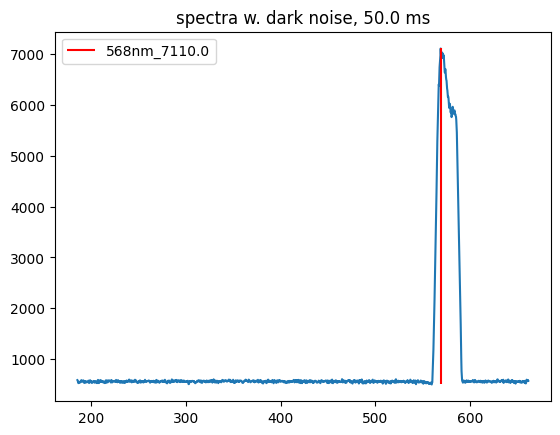

In [301]:
labelled_nm =575
micro_time =.05*1e6
spec.integration_time_micros(micro_time)

start = time.perf_counter()
ints = spec.intensities()
elapsed = time.perf_counter() - start
print(f'{elapsed} second')
if np.max(ints)<MAX_SPEC and np.max(ints)>MIN_SPEC:
    print("max read out in range")
    plt.plot(nm,ints)
    # plt.plot(nm,ints-dark_)
    plt.vlines(nm[np.argmax(ints)],np.min(ints),np.max(ints),color='r',label=f'{int(nm[np.argmax(ints)])}nm_{np.max(ints)}')
    plt.title(f'spectra w. dark noise, {micro_time/1e3} ms')
    # plt.ylim(np.min(ints),np.max(ints))
    plt.legend()
elif np.max(ints)>MAX_SPEC:
    print("reduce integration time")
elif np.max(ints)<MIN_SPEC:
    print("increase integration time")
else:
    print("bug")

In [302]:
wv=nm[np.argmax(ints)]

spectra =np.zeros((10,1516))
for rep in range(10):
    #spec.integration_time_micros(micro_time)
    start = time.perf_counter()
    _,spectra[rep] = spec.spectrum()
    elapsed = time.perf_counter() - start
    print(f'{elapsed} second')
    time.sleep(2)
np.save(f'./ST_UV_calibration_01092026/SETUP2_{labelled_nm}nm_LED_peak{int(round(wv,0))}nm_{micro_time/1e3}ms.npy',spectra)    

0.05550285799836274 second
0.05590244799896027 second
0.056031066000286955 second
0.05643440999847371 second
0.05645179999919492 second
0.054645242998958565 second
0.056129731001419714 second
0.0558979220004403 second
0.05567958699975861 second
0.055099608998716576 second


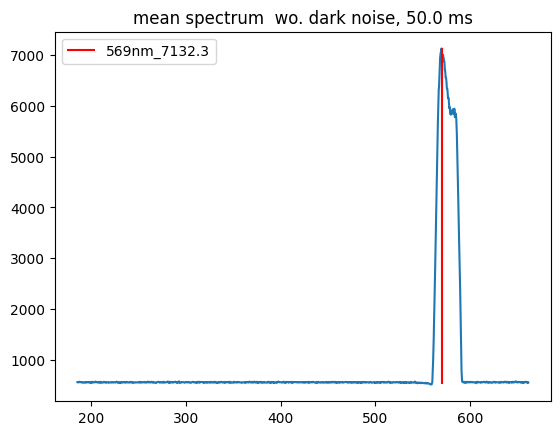

In [303]:
to_pickle_spectra= np.mean(spectra,axis=0)
plt.plot(nm,to_pickle_spectra)
plt.vlines(nm[np.argmax(to_pickle_spectra)],np.min(to_pickle_spectra),np.max(to_pickle_spectra),color='r',label=f'{int(nm[np.argmax(to_pickle_spectra)])}nm_{np.max(to_pickle_spectra)}')
plt.title(f'mean spectrum  wo. dark noise, {micro_time/1e3} ms')
plt.legend()

## turn off LED

0.05481869299910613 second
max read out in range


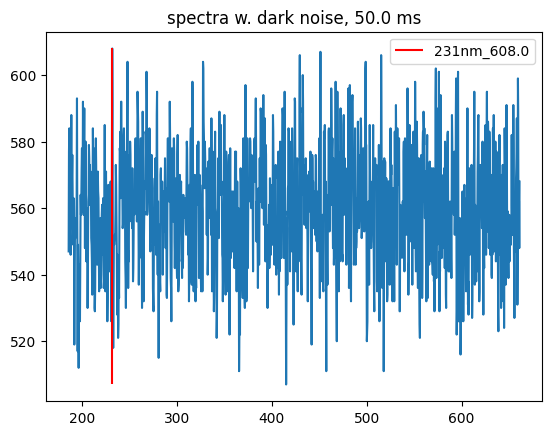

In [304]:
# check spectra before measuring darknoise
start = time.perf_counter()
ints = spec.intensities()
elapsed = time.perf_counter() - start
print(f'{elapsed} second')

print("max read out in range")
plt.plot(nm,ints)
# plt.plot(nm,ints-dark_)
plt.vlines(nm[np.argmax(ints)],np.min(ints),np.max(ints),color='r',label=f'{int(nm[np.argmax(ints)])}nm_{np.max(ints)}')
plt.title(f'spectra w. dark noise, {micro_time/1e3} ms')
# plt.ylim(np.min(ints),np.max(ints))
plt.legend()

In [305]:
# turn off the light source
darknoises =np.zeros((10,1516))
for rep in range(10):
    #spec.integration_time_micros(micro_time)
    start = time.perf_counter()
    _,darknoises[rep] = spec.spectrum()
    elapsed = time.perf_counter() - start
    print(f'{elapsed} second')
    time.sleep(2)
np.save(f'./ST_UV_calibration_01092026/dark/SETUP2_{labelled_nm}nm_LED_peak{int(round(wv,0))}nm_{micro_time/1e3}ms_darknoise.npy',darknoises)    


0.05488120100199012 second
0.05528029500055709 second
0.055758485999831464 second
0.05597710399888456 second
0.056548350999946706 second
0.05636229700030526 second
0.055951107999135274 second
0.05636303199935355 second
0.05641408799783676 second
0.05668078400049126 second


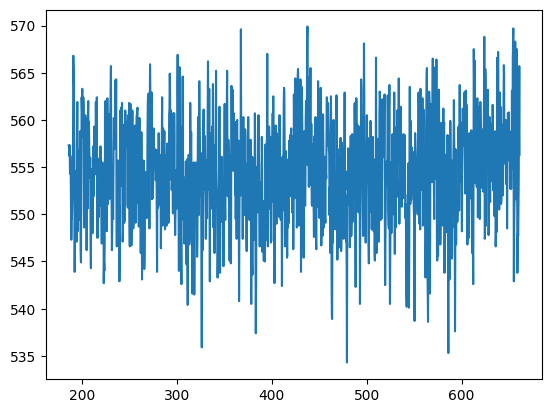

In [306]:
to_pickle_darknoise= np.mean(darknoises,axis=0)
plt.plot(nm,to_pickle_darknoise)

## SWITCH ON THE LED

0.05477635599891073 second
max read out in range


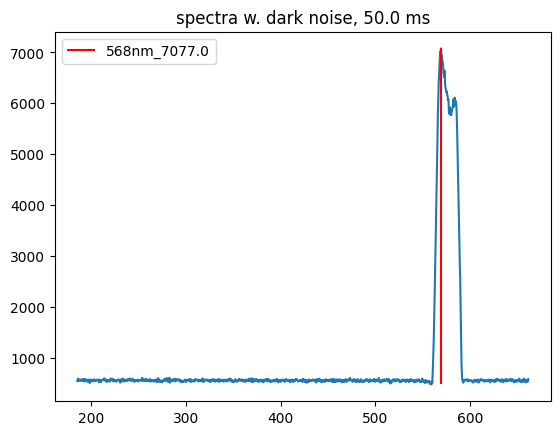

In [307]:
# sanity check
start = time.perf_counter()
ints = spec.intensities()
elapsed = time.perf_counter() - start
print(f'{elapsed} second')

print("max read out in range")
plt.plot(nm,ints)
# plt.plot(nm,ints-dark_)
plt.vlines(nm[np.argmax(ints)],np.min(ints),np.max(ints),color='r',label=f'{int(nm[np.argmax(ints)])}nm_{np.max(ints)}')
plt.title(f'spectra w. dark noise, {micro_time/1e3} ms')
# plt.ylim(np.min(ints),np.max(ints))
plt.legend()

## USE POWER METER NOW

In [308]:
test = to_pickle_spectra-to_pickle_darknoise

In [309]:
int(round(nm[np.argmax(test)],0))

570

In [310]:
power_nm = int(round(nm[np.argmax(to_pickle_spectra)],0))
print(f'adjust the wavelength of the powermeter to \n {power_nm} nm')

adjust the wavelength of the powermeter to 
 570 nm


## read the powermeter without the head

In [311]:
preproed_dict = {
    'int_t':int(micro_time), # micro-second
    'spectrum_corr':to_pickle_spectra,
    'ts':datetime.datetime.now(),
    'power':78, # unit nW
}
with open(f'./ST_UV_calibration_01092026/pkl/SETUP2_{labelled_nm}nm_peak{power_nm}.pkl', 'wb') as f:
    pickle.dump(preproed_dict, f)

In [171]:
# save this along w. ST-UV's (1516,) wavlength
power_dark = 0.4 # nW